# Exploratory Analysis of Book Datasets with Python

### 1.0 Introduction
This project was originally completed for the *Programming with Data* university module and has been revised for a public GitHub portfolio. It uses Python programming techniques to explore a dataset of interest and document the analysis process. 

Books have long been an important source of information and are an interesting subject for data exploration. Quantitative and categorical attributes, including ratings and book length, can help describe patterns in how books are represented and evaluated. I also chose this topic because of my personal interest in books.  

This project presents an exploratory data analysis of cleaned and structured book datasets to identify trends, relationships and potential patterns. It combines Python programming with a structured approach to research, data preparation and presentation. I document the steps and decisions so that the analysis can be followed and reproduced.

### 2.0 Research Aims and Objectives
The primary aim is to explore trends and possible relationships in book data and consider what these patterns suggest about recorded ratings. My objectives are to clean and organise the dataset, summarise book characteristics such as length and rating counts, and assess whether any associations are visible. I use Python programming techniques introduced in the module to carry out this work.

Research question:
*What factors contribute to readers' preferences?*

For this exploratory analysis, I use average book ratings and rating counts as measurable indicators. These are aggregated book-level data, not individual readers' responses, so any relationships found are descriptive rather than causal.


### 3.0 Background
This study explores book ratings and popularity using a public book dataset. I also considered web scraping as an alternative data-collection method, but did not collect from commercial review sites without establishing permission. The project instead demonstrates scraping using *Books to Scrape*, a site designed for web-scraping practice. Its prices and ratings are fictional, so this second dataset demonstrates the method rather than providing evidence about actual readers. 

### 4.0 Data 
This section describes the datasets and how they are structured. Understanding the format, variables and potential problems is an important step before analysis. Data cleaning can include checking completeness, handling missing or inconsistent values, converting data types and validating records. It improves data quality, although it cannot guarantee that all source data are accurate.

#### 4.1 Data Validity
Data validity directly affects the analysis and its conclusions. A dataset may be outdated, inconsistent or incomplete. I therefore inspect the data for structure, completeness, expected values and relevance to the research question before interpreting the results.  

#### 4.2 Data Collection 
Data can be collected through surveys, observations, web-based sources and other methods. For this project, I selected a publicly available book dataset from Kaggle because it was suitable for demonstrating data cleaning and analysis within the module's scope. Third-party datasets can contain errors or incomplete descriptions, so I examine the records before relying on them.  

In addition to Kaggle, I explored web scraping as a data-collection technique. I considered book-selling and review websites but used *Books to Scrape* for the practical exercise because it is intended for this purpose. 

The Kaggle dataset provides the main analysis. The separate *Books to Scrape* sample shows how HTML data can be collected and formatted, but it is not used to validate findings about readers.

#### 4.3 Data Dictionary

A fundamental aspect of any data analysis is developing a thorough understanding of the dataset. This includes not only understanding column names but also any more complex data attributes and their relationships.

**books.csv file**

The dataset contains the following fields: *bookID, title, authors, average_rating, isbn, isbn13, language_code, num_pages, ratings_count, text_reviews_count, publication_date, publisher*.

Most field names are self-explanatory. **ISBN-10** and **ISBN-13** are identifiers rather than numerical measures: ISBN-13 includes a prefix, registration-group information, a publisher/registrant element, a publication element and a check digit. These fields should be treated as text, and ISBN segments are not used as a substitute for the dataset's `language_code`.

**Decision:** I remove the `isbn` column from the analysis sample because it is not needed for the research question. The `isbn13` identifier is retained as text. I also inspect the different English-language codes before selecting the sample.

### 5.0 Methodology
I apply the data exploration and programming techniques learned in the module, drawing also on my earlier Google Data Analytics studies and ideas from Saunders et al. (2019). The aim is to make the steps clear and connect the methods to the research question.

#### 5.1 Tools and libraries used and for what:
* Analysis in Python libraries and tools:
    - Pandas - enhanced dataset cleaning, manipulation and analysis library. 
    - csv - built-in module for reading CSV records
    - Matplotlib and Seaborn - libraries for visualisation
    - NumPy - numerical operations and chart bins
* Libraries and tools for web scraping:
  - Beautiful Soup - library for web navigation and data scraping
  - requests - library for data fetching from the web
  - pandas - used to structure scraped data into a table

#### 5.2 Summary of step-by-step process of analysis.
This section outlines the main stages of data processing and analysis. The workflow is based on the module's learning outcomes and my earlier notes from the Google Data Analytics course and Saunders et al. (2019).

  1. Define the research question and objectives
  2. Data collection, storage and data management.  
     - Explore data sources, and determine the dataset suitable to answer research questions.
     - Check the credibility, legality and licensing of the dataset collection, handling and sharing. 
     - Understand your dataset and format, identify data structure, data types, etc. 
     - Determine possible techniques for dataset analysis to draw meaningful conclusions.
  3. Data cleaning and integrity.
     - Handle inaccuracies, missing values, illegal values, and duplicates.
     - Transform into a useful format.
     - Check and handle outliers (out-of-bound values).
     - Validate the data for completeness and correctness.
  4. Data exploration, presentation and analysis
     - Use Python functions for calculations, regular expressions for text extraction and LaTeX for presenting formulas.
     - Check again with research questions and objectives.
     - Create appropriate data structures for the result visualisation.
  5. Communicating data insights and findings, interpreting results
      - Data Storytelling: base data interpretations on data findings.
      - Recognise gaps and future development opportunities for the analysis.

### 6.0 Limitations and Constraints
The analysis originated as coursework with a limited timeframe. This portfolio version retains the project's exploratory scope rather than adding predictive models or methods beyond the original research objectives.

### 7.0 Ethics and Bias
The main book dataset was supplied through Kaggle and is attributed in the references. Before redistributing data, its source and licensing terms should be checked. *Books to Scrape* is a demonstration website designed for scraping practice; its ratings and prices are randomly assigned and should not be interpreted as real market or reader behaviour.

Important limitations and potential biases include:
- The selection is restricted to four English-language labels, so it cannot represent all languages or geographical regions.
- Goodreads ratings come from self-selected platform users, not a random sample of all readers.
- The dataset may contain multiple editions of a book and covers only a particular historical snapshot.
- Excluding short books and titles containing terms such as “collection” or “volume” changes which types of books are represented.

These restrictions affect the interpretation of the findings. The project investigates associations between recorded attributes rather than identifying what causes individual readers to prefer a book.


### 8.0 Data Processing, Exploration and Analysis

I begin by importing the main CSV dataset and reviewing its structure: column names, row alignment, missing or inconsistent values and numeric data types. This initial inspection determines which cleaning steps are necessary before analysis.


In [1]:
import csv
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the raw CSV first to identify rows with an unexpected number of fields.
with open("data/books.csv", mode="r", encoding="utf-8", newline="") as csvfile:
    book_list = list(csv.reader(csvfile))

print("First three records (including the header):")
for row in book_list[:3]:
    print(row)


First three records (including the header):
['bookID', 'title', 'authors', 'average_rating', 'isbn', 'isbn13', 'language_code', '  num_pages', 'ratings_count', 'text_reviews_count', 'publication_date', 'publisher']
['1', 'Harry Potter and the Half-Blood Prince (Harry Potter  #6)', 'J.K. Rowling/Mary GrandPré', '4.57', '0439785960', '9780439785969', 'eng', '652', '2095690', '27591', '9/16/2006', 'Scholastic Inc.']
['2', 'Harry Potter and the Order of the Phoenix (Harry Potter  #5)', 'J.K. Rowling/Mary GrandPré', '4.49', '0439358078', '9780439358071', 'eng', '870', '2153167', '29221', '9/1/2004', 'Scholastic Inc.']


### Formatting Data Sample

An unfamiliar dataset can be inspected in a spreadsheet for an initial overview, but I use a pandas DataFrame for the actual cleaning and analysis. The first row of the CSV contains column names. Before converting the records into a DataFrame, I check whether every data row has the same number of fields as the header.

The first inspection reveals that a small number of rows have one additional field, which needs to be corrected.


In [2]:
print("Number of columns in the header:", len(book_list[0]))

# Identify the records that do not match the 12-column header.
problematic_rows = [row for row in book_list[1:] if len(row) != len(book_list[0])]
print("Records with an unexpected number of columns:", len(problematic_rows))
for row in problematic_rows:
    print(row[0], "—", len(row), "columns:", row[2:4])


Number of columns in the header: 12
Records with an unexpected number of columns: 4
12224 — 13 columns: ['Sam Bass Warner', ' Jr./Sam B. Warner']
16914 — 13 columns: ['David E. Smith (Turgon of TheOneRing.net', ' one of the founding members of this Tolkien website)/Verlyn Flieger/Turgon (=David E. Smith)']
22128 — 13 columns: ['James Wesley', ' Rawles']
34889 — 13 columns: ['Brown', ' Son & Ferguson']


**Reason:** Four CSV records have 13 fields rather than 12. Their author names contain commas that were not enclosed in quotation marks, so the CSV reader treats part of the author name as an extra field. The rating and all subsequent values are shifted one position.

**Decision:** Join the two fragments of the author field instead of deleting either one. This preserves information and restores the expected 12-column structure.


In [3]:
def repair_row(row):
    # The extra comma splits the author field into positions 2 and 3.
    if len(row) == 13:
        return row[:2] + [",".join(row[2:4])] + row[4:]
    if len(row) != 12:
        raise ValueError(f"Unexpected number of fields: {len(row)}")
    return row

repaired_rows = [repair_row(row) for row in book_list[1:]]
header = [name.strip() for name in book_list[0]]
df = pd.DataFrame(repaired_rows, columns=header)

print("Dataset dimensions:", df.shape)
df.head()


Dataset dimensions: (11127, 12)


,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,9/13/2004,Scholastic


In [4]:
# Check one previously malformed record after the repair.
print(df.loc[df["bookID"] == "16914", ["bookID", "title", "authors", "average_rating"]].to_string(index=False))


bookID                             title                                                                                                                                authors average_rating
 16914 The Tolkien Fan's Medieval Reader David E. Smith (Turgon of TheOneRing.net, one of the founding members of this Tolkien website)/Verlyn Flieger/Turgon (=David E. Smith)           3.58


### Checking Data Types

To prepare the DataFrame for calculations, I check its column types, non-null counts and possible missing values. `df.info()` is useful for inspecting these properties and verifying that the DataFrame has the expected structure.

The raw CSV stores the values as strings. Columns used for numerical analysis, including `num_pages`, `ratings_count` and `average_rating`, therefore need to be converted. ISBN fields remain text because they are identifiers rather than quantities.


In [5]:
df.columns = df.columns.str.strip()

# Convert only measured quantities; keep ISBN values and book IDs as identifiers.
numeric_columns = ["num_pages", "ratings_count", "text_reviews_count", "average_rating"]
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11127 entries, 0 to 11126
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bookID              11127 non-null  object 
 1   title               11127 non-null  object 
 2   authors             11127 non-null  object 
 3   average_rating      11127 non-null  float64
 4   isbn                11127 non-null  object 
 5   isbn13              11127 non-null  object 
 6   language_code       11127 non-null  object 
 7   num_pages           11127 non-null  int64  
 8   ratings_count       11127 non-null  int64  
 9   text_reviews_count  11127 non-null  int64  
 10  publication_date    11127 non-null  object 
 11  publisher           11127 non-null  object 
dtypes: float64(1), int64(3), object(8)
memory usage: 1.0+ MB


In [6]:
# Inspect the range and number of distinct average ratings for unusual values.
print("Rating range:", df["average_rating"].min(), "to", df["average_rating"].max())
print("Distinct average ratings:", df["average_rating"].nunique())
print("Missing numeric values:")
print(df[numeric_columns].isna().sum())


Rating range: 0.0 to 5.0
Distinct average ratings: 209
Missing numeric values:
num_pages             0
ratings_count         0
text_reviews_count    0
average_rating        0
dtype: int64


### Handling Inconsistent Data and Outliers

During inspection, I noticed entries with zero pages or no recorded ratings. These records are not informative for the intended comparison between book length and rating, so I exclude them from the main analysis.

**Decision:** Keep books with more than 50 pages and at least one recorded rating. The page threshold is a practical selection rule from the original project, **not** a claim that shorter works are invalid books. It excludes some children's books, poems and other short publications, which limits the interpretation.


In [7]:
# Retain books with sufficient page information and at least one rating.
eligible_books = df[(df["num_pages"] > 50) & (df["ratings_count"] > 0)].copy()
print("Rows after the page and rating-count filters:", len(eligible_books))
eligible_books.head()


Rows after the page and rating-count filters: 10494


,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,9/13/2004,Scholastic


During the initial overview, I also noticed records with more than 1,500 pages, including multi-volume sets and collections. These can be difficult to compare directly with individual books, so I examine them before making a final filtering decision.


In [8]:
books_1500 = df[df["num_pages"] > 1500]
print("Books over 1,500 pages:", len(books_1500))
print(books_1500[["title", "num_pages"]].head(15).to_string(index=False))


Books over 1,500 pages: 29
                                                                                 title  num_pages
                                Harry Potter Boxed Set  Books 1-5 (Harry Potter  #1-5)       2690
                                          Harry Potter Collection (Harry Potter  #1-6)       3342
                 J.R.R. Tolkien 4-Book Boxed Set: The Hobbit and The Lord of the Rings       1728
                                                                 The Iliad/The Odyssey       1556
                                                      The Complete Pelican Shakespeare       1808
               The History of the Lord of the Rings (The History of Middle-earth #6-9)       1680
              The Complete Anne of Green Gables Boxed Set (Anne of Green Gables  #1-8)       2088
                         The New Annotated Sherlock Holmes: The Complete Short Stories       1878
                                                                 Plato: Complete Works     

**Reason:** Some records describe sets, volumes or collections rather than a single title, and these can affect the page-length distribution.

**Decision:** As in the original project, exclude books above 1,500 pages and titles containing words such as “volumes”, “set” or “collection”. This title-based rule is imperfect: it may also remove genuine single-volume works, so I acknowledge this limitation in the conclusions.


### Forming the Data Sample

The dataset contains books in different languages. To choose an appropriate sample for this analysis, I first inspect the number of records for each language code.

Some English-language records use regional labels. Excluding those labels would unnecessarily remove relevant books, so the final sample includes `eng`, `en-US`, `en-GB` and `en-CA`.


In [9]:
distinct_language_codes = df["language_code"].value_counts()
print(distinct_language_codes)

# Review a few entries from a different language code.
print(df.loc[df["language_code"] == "jpn", ["title", "language_code"]].head())


language_code
eng      8911
en-US    1409
spa       218
en-GB     214
fre       144
ger        99
jpn        46
mul        19
zho        14
grc        11
por        10
en-CA       7
ita         5
enm         3
lat         3
rus         2
swe         2
ara         1
nl          1
srp         1
msa         1
glg         1
wel         1
nor         1
tur         1
gla         1
ale         1
Name: count, dtype: int64
                                        title language_code
872                        DEATH NOTE デスノート 1           jpn
873   Death Note  Vol. 4: 恋心 (Death Note  #4)           jpn
874   Death Note  Vol. 3: 激走 (Death Note  #3)           jpn
881   Bleach―ブリーチ― 1 [Burīchi 1] (Bleach  #1)           jpn
3756                                  彼方から 13           jpn


**Decision:** Restrict the main sample to books with one of the four English-language codes: `eng`, `en-US`, `en-GB` and `en-CA`.

**Reason:** Working with one language group keeps the analysis more consistent and manageable within the project scope. Unlike the original `eng`-only filter, this includes regional English labels. It does **not** remove all duplicate editions, and it means the findings should not be generalised to books in other languages.


### Filtering Unnecessary Data

The final selection applies the cleaning decisions made above:
- Keep only the four English-language codes.
- Keep records with 51–1,500 pages and at least one rating.
- Remove rows whose author is `NOT A BOOK`.
- Exclude titles matching the original broad “vol”, “set” or “collection” keyword rule.
- Drop the `isbn` column, which is not needed for the analysis, and reset the row index.

The original CSV remains unchanged; these rules apply only to the analysis DataFrame.


In [10]:
english_codes = ["eng", "en-US", "en-GB", "en-CA"]
collection_terms = r"\b(?:vol|vols|volumes|set|sets|collection|collections)\b"

processed_books_csv = (
    eligible_books.loc[
        eligible_books["language_code"].isin(english_codes)
        & (eligible_books["authors"] != "NOT A BOOK")
        & (eligible_books["num_pages"] <= 1500)
        & ~eligible_books["title"].str.contains(collection_terms, case=False, na=False)
    ]
    .drop(columns=["isbn"])
    .reset_index(drop=True)
    .copy()
)

print(f"Selected {len(processed_books_csv):,} of {len(df):,} original records.")
print(processed_books_csv["language_code"].value_counts())
processed_books_csv.head()


Selected 9,664 of 11,127 original records.
language_code
eng      8177
en-US    1279
en-GB     201
en-CA       7
Name: count, dtype: int64


,bookID,title,authors,average_rating,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,9,"Unauthorized Harry Potter Book Seven News: ""Ha...",W. Frederick Zimmerman,3.74,9780976540601,en-US,152,19,1,4/26/2005,Nimble Books


### Readability

Some book titles are long, which can make a DataFrame harder to read. I adjust the displayed width of the cells while keeping the underlying text unchanged. This is a presentation change only and does not affect the analysis.


In [11]:
processed_books_csv.head(10).style.set_table_styles(
    [{"selector": "th, td", "props": [
        ("max-width", "400px"), ("text-align", "left"),
        ("white-space", "nowrap"), ("overflow", "hidden")
    ]}]
)


,bookID,title,authors,average_rating,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry Potter #6),J.K. Rowling/Mary GrandPré,4.570000,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Harry Potter #5),J.K. Rowling/Mary GrandPré,4.490000,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry Potter #2),J.K. Rowling,4.420000,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harry Potter #3),J.K. Rowling/Mary GrandPré,4.560000,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,9,"Unauthorized Harry Potter Book Seven News: ""Half-Blood Prince"" Analysis and Speculation",W. Frederick Zimmerman,3.740000,9780976540601,en-US,152,19,1,4/26/2005,Nimble Books
5,12,The Ultimate Hitchhiker's Guide: Five Complete Novels and One Story (Hitchhiker's Guide to the Galaxy #1-5),Douglas Adams,4.380000,9780517226957,eng,815,3628,254,11/1/2005,Gramercy Books
6,13,The Ultimate Hitchhiker's Guide to the Galaxy (Hitchhiker's Guide to the Galaxy #1-5),Douglas Adams,4.380000,9780345453747,eng,815,249558,4080,4/30/2002,Del Rey Books
7,14,The Hitchhiker's Guide to the Galaxy (Hitchhiker's Guide to the Galaxy #1),Douglas Adams,4.220000,9781400052929,eng,215,4930,460,8/3/2004,Crown
8,18,The Ultimate Hitchhiker's Guide (Hitchhiker's Guide to the Galaxy #1-5),Douglas Adams,4.380000,9780517149256,eng,815,2877,195,1/17/1996,Wings Books
9,21,A Short History of Nearly Everything,Bill Bryson,4.210000,9780767908184,eng,544,248558,9396,9/14/2004,Broadway Books


### Further Outliers

To inspect unusual ratings, I examine the top and bottom 1% of the selected books. Extreme ratings are not automatically incorrect: some may come from books with very few votes. This step helps identify records worth checking rather than proving that the values are errors.


In [12]:
top_percent_count = max(1, int(len(processed_books_csv) * 0.01))
top_1_rated_books = processed_books_csv.nlargest(top_percent_count, "average_rating")
print("Books in top 1%:", len(top_1_rated_books))
display(top_1_rated_books[["title", "authors", "average_rating", "ratings_count"]].head(10))


Books in top 1%: 96


,title,authors,average_rating,ratings_count
700,Willem de Kooning: Late Paintings,Julie Sylvester/David Sylvester,5.0,1
1105,Middlesex Borough (Images of America: New Jersey),Middlesex Borough Heritage Committee,5.0,2
3594,Zone of the Enders: The 2nd Runner Official St...,Tim Bogenn,5.0,2
4191,The Diamond Color Meditation: Color Pathway to...,John Diamond,5.0,5
4303,Bulgakov's the Master and Margarita: The Text ...,Elena N. Mahlow,5.0,4
4382,The Complete Theory Fun Factory: Music Theory ...,Ian Martin/Katie Elliott,5.0,1
4933,Winchester Shotguns,Dennis Adler/R.L. Wilson,5.0,2
4934,Colossians and Philemon: A Critical and Exeget...,R. McL. Wilson,5.0,1
5328,Taxation of Mineral Rents,Ross Garnaut,5.0,1
5383,The New Big Book of America,Todd Davis/Marc Frey,5.0,2


I also inspect the bottom 1% of average ratings. For both groups, the number of recorded ratings is important context: a rating based on one vote is not directly comparable with a rating based on thousands of votes.


In [13]:
bottom_1_rated_books = processed_books_csv.nsmallest(top_percent_count, "average_rating")
print("Books in bottom 1%:", len(bottom_1_rated_books))
display(bottom_1_rated_books[["title", "authors", "average_rating", "ratings_count"]].head(10))


Books in bottom 1%: 96


,title,authors,average_rating,ratings_count
2857,Puzzle Pack: The Witch of Blackbird Pond,Mary B. Collins,1.00,2
6914,The Art of Loving by Erich Fromm: A True Story...,Lala Okamoto,1.67,3
3402,The Boys of the Archangel Raphael: A Youth Con...,Konrad Eisenbichler,2.00,1
4835,McDougal Littell Science: Student Edition Grad...,McDougal Littell/Douglas W. Carnine,2.00,3
5886,The Two Tocquevilles Father and Son,R.R. Palmer,2.00,1
7016,The Earth and Its Peoples: A Global History V...,Richard W. Bulliet/Pamela Kyle Crossley/Steven...,2.00,1
9648,The Die Broke Financial Problem Solver,Stephen M. Pollan/Mark LeVine,2.33,3
7636,Citizen Girl,Emma McLaughlin/Nicola Kraus,2.40,5415
5595,Field Guide to Home Buying in America,Mark LeVine/Michael Pollan/Stephen M. Pollan,2.50,4
3881,The Trouble with the Pears: An Intimate Portra...,Gia Bathory Al Babel,2.55,33


### Statistical Exploration

After preparing the data sample, I calculate measures of central tendency and spread. These summarise the observations; filtering unusual values does not imply that the data follow a normal distribution.

The mean is the sum of the observations divided by the number of observations:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$

The mode is the most frequent observed value:

$$\operatorname{Mode} = \operatorname*{arg\,max}_{x} f(x)$$


In [14]:
mean_pages = processed_books_csv["num_pages"].mean()
mean_ratings = processed_books_csv["average_rating"].mean()
print(f"Mean number of pages: {mean_pages:.1f}")
print(f"Mean average rating: {mean_ratings:.2f}")

mode_pages = processed_books_csv["num_pages"].mode()[0]
mode_author = processed_books_csv["authors"].mode()[0]
mode_publisher = processed_books_csv["publisher"].mode()[0]
print(f"Most common number of pages: {mode_pages}")
print(f"Most common author: {mode_author}")
print(f"Most common publisher: {mode_publisher}")

std_ratings = processed_books_csv["ratings_count"].std()
std_pages = processed_books_csv["num_pages"].std()
print(f"Standard deviation of ratings count: {std_ratings:.1f}")
print(f"Standard deviation of number of pages: {std_pages:.1f}")


Mean number of pages: 348.2
Mean average rating: 3.93
Most common number of pages: 288
Most common author: P.G. Wodehouse
Most common publisher: Vintage


Standard deviation of ratings count: 120311.7
Standard deviation of number of pages: 203.2


### Data Grouping

Grouping books by page range helps present patterns in the dataset. I compare the average book rating and mean number of recorded ratings within each group. The groups are useful for visualisation, but correlations are calculated from **individual book records** rather than from group averages.


In [15]:
bins = [50, 200, 300, 500, 700, 900, 1100, 1500]
labels = ["51–200", "201–300", "301–500", "501–700", "701–900", "901–1100", "1101–1500"]

processed_books_csv["page_range"] = pd.cut(
    processed_books_csv["num_pages"], bins=bins, labels=labels, include_lowest=True
)

# Group summaries are descriptive; each row represents multiple books.
grouped_data = (
    processed_books_csv.groupby("page_range", observed=True)
    .agg(
        books=("bookID", "size"),
        average_ratings=("average_rating", "mean"),
        average_ratings_count=("ratings_count", "mean")
    )
    .reset_index()
)
display(grouped_data.round(2))


,page_range,books,average_ratings,average_ratings_count
0,51–200,2091,3.90,12888.90
1,201–300,2456,3.89,17737.26
2,301–500,3569,3.92,23346.67
3,501–700,951,4.01,26783.29
4,701–900,357,4.08,28514.82
5,901–1100,141,4.14,24673.95
6,1101–1500,99,4.21,19765.27


In [16]:
# Correlation is calculated per book, not from the seven page-range averages.
ratings_correlation = processed_books_csv["average_rating"].corr(
    processed_books_csv["ratings_count"]
)
print(f"Correlation: mean rating vs number of ratings = {ratings_correlation:.3f}")


Correlation: mean rating vs number of ratings = 0.049


In [17]:
length_correlation = processed_books_csv["num_pages"].corr(
    processed_books_csv["average_rating"]
)
print(f"Correlation: number of pages vs mean rating = {length_correlation:.3f}")


Correlation: number of pages vs mean rating = 0.203


Pearson's correlation coefficient ranges from -1 to +1. A value close to zero suggests little linear association, while a larger absolute value indicates a stronger linear relationship.

The book-level correlation between the **number of recorded ratings and average rating** is approximately **0.049**, which is almost zero. The correlation between **book length and average rating** is approximately **0.203**, indicating a weak positive association.

The original project calculated the second correlation from seven aggregated page bands and reported a much stronger coefficient. This revision uses the individual books as observations. A weak correlation does not show that longer books cause better ratings, and the dataset alone cannot establish why readers prefer particular books.


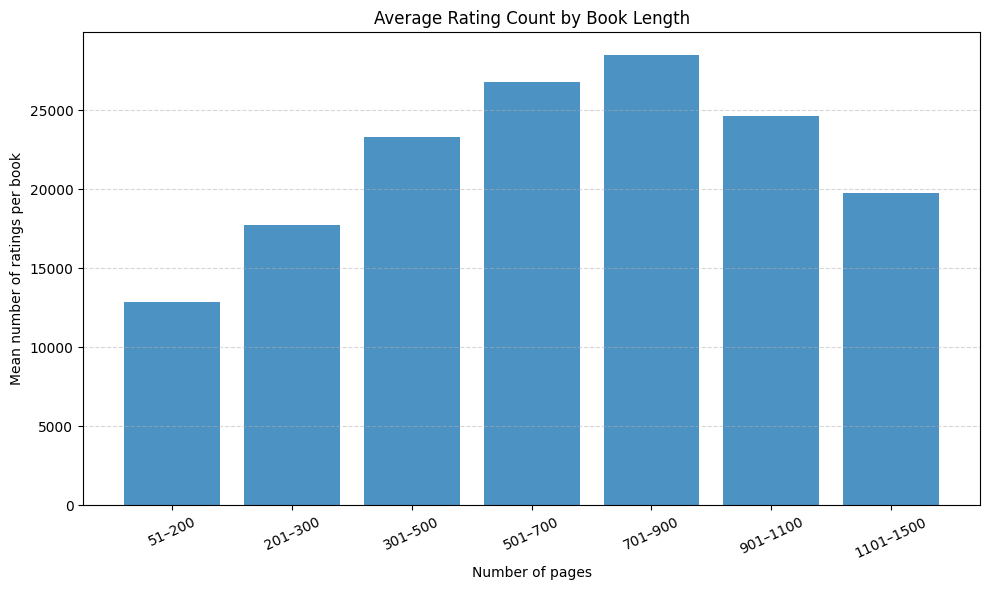

In [18]:
plt.figure(figsize=(10, 6))
plt.bar(grouped_data["page_range"].astype(str), grouped_data["average_ratings_count"], alpha=0.8)
plt.xlabel("Number of pages")
plt.ylabel("Mean number of ratings per book")
plt.title("Average Rating Count by Book Length")
plt.xticks(rotation=25)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [19]:
# Extract the year as a separate numeric column for exploring publication dates.
processed_books_csv["publication_year"] = pd.to_numeric(
    processed_books_csv["publication_date"].str.extract(r"(\b\d{4}\b)", expand=False),
    errors="coerce"
)
print(processed_books_csv["publication_year"].head())


0    2006
1    2004
2    2003
3    2004
4    2005
Name: publication_year, dtype: int64


In [20]:
# Years with very few books can have unstable mean ratings.
best_publishing_years = (
    processed_books_csv.groupby("publication_year", dropna=True)
    .agg(average_rating=("average_rating", "mean"), books=("bookID", "size"))
)
print("Publication years with at least 10 books, ranked by mean rating:")
display(best_publishing_years.loc[best_publishing_years["books"] >= 10]
        .sort_values("average_rating", ascending=False).head(10).round(2))


Publication years with at least 10 books, ranked by mean rating:


,average_rating,books
publication_year,,
2013,4.06,13
1974,4.05,11
1969,4.05,11
1985,4.03,52
1975,4.03,13
1971,4.02,10
1984,4.02,64
1990,4.01,109
1977,4.01,30


### Data Analysis and Visualisation

The following scatter plot compares book length and average ratings directly. Each point represents a single record in the selected dataset.


#### Book Number of Pages vs Book Ratings


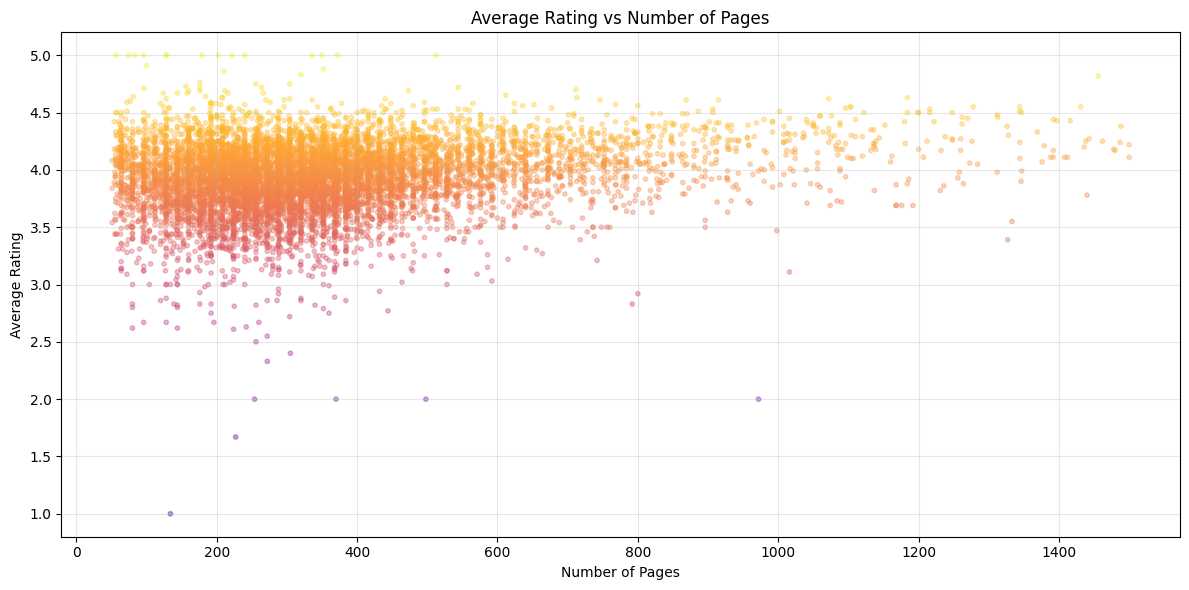

In [21]:
plt.figure(figsize=(12, 6))
plt.scatter(
    processed_books_csv["num_pages"],
    processed_books_csv["average_rating"],
    c=processed_books_csv["average_rating"],
    cmap="plasma", alpha=0.35, s=10
)
plt.xlabel("Number of Pages")
plt.ylabel("Average Rating")
plt.title("Average Rating vs Number of Pages")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Most books in this sample have average ratings around four, across a wide range of book lengths. There is substantial variation, especially among shorter books. The computed book-level correlation is weak and positive, so the scatter plot should not be interpreted as evidence that longer books necessarily receive better ratings. This plot concerns *average ratings*, not the number of votes.


### 9.0 Data Scraping Method

Web scraping is an alternative way to collect book information from HTML. In this part, I demonstrate the method using [Books to Scrape](https://books.toscrape.com/), a practice website containing fictional books, prices and ratings.

The original coursework scraped the site's first page and saved 20 results. For reproducibility, this notebook uses that **saved CSV sample by default** so it runs without network access. Set `RUN_LIVE_SCRAPE = True` to fetch and parse the current first page using `requests` and Beautiful Soup.


In [22]:
from bs4 import BeautifulSoup
import requests

url = "https://books.toscrape.com/"
RUN_LIVE_SCRAPE = False

if RUN_LIVE_SCRAPE:
    response = requests.get(url, timeout=15)
    response.raise_for_status()
    soup = BeautifulSoup(response.content, "html.parser")
    print("Fetched a live HTML page successfully.")
else:
    print("Using the preserved 20-book scraping sample (offline mode).")


Using the preserved 20-book scraping sample (offline mode).


HTML parsing converts raw web-page elements into a structure that Python can process. In the live option, Beautiful Soup finds each book's `<article>` element and extracts its title, star-rating class and displayed price.

The saved version keeps the values collected in the original project. Both approaches produce a DataFrame that can be formatted and analysed using pandas.


In [23]:
if RUN_LIVE_SCRAPE:
    books_scraped = []
    for book_item in soup.find_all("article", class_="product_pod"):
        title = book_item.h3.a["title"]
        rating = book_item.find("p", class_="star-rating")["class"][1]
        price = book_item.find("p", class_="price_color").get_text(strip=True)
        books_scraped.append({"title": title, "rating": rating, "price": price})
    books_scraped_df = pd.DataFrame(books_scraped)
else:
    books_scraped_df = pd.read_csv("data/scraped_books_sample.csv")

print("Scraped-data example:", len(books_scraped_df), "records")
display(books_scraped_df.head(10))


Scraped-data example: 20 records


,title,rating,price
0,A Light in the Attic,Three,£51.77
1,Tipping the Velvet,One,£53.74
2,Soumission,One,£50.10
3,Sharp Objects,Four,£47.82
4,Sapiens: A Brief History of Humankind,Five,£54.23
5,The Requiem Red,One,£22.65
6,The Dirty Little Secrets of Getting Your Dream...,Four,£33.34
7,The Coming Woman: A Novel Based on the Life of...,Three,£17.93
8,The Boys in the Boat: Nine Americans and Their...,Four,£22.60
9,The Black Maria,One,£52.15


In [24]:
print(books_scraped_df.dtypes)


title     object
rating    object
price     object
dtype: object


### Formatting Data

The ratings are initially words, such as `One` and `Five`, while prices are strings containing the pound symbol. I convert both columns to numeric values to make basic summaries and plots possible.

The rating mapping below follows the 1–5 scale displayed on the training website. These values are artificially assigned and should not be treated as real user feedback.


In [25]:
rating_mapping = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

books_scraped_df["rating"] = books_scraped_df["rating"].map(rating_mapping)
books_scraped_df["price"] = (
    books_scraped_df["price"].str.replace("£", "", regex=False).astype(float)
)

print(books_scraped_df.dtypes)
display(books_scraped_df.head())


title      object
rating      int64
price     float64
dtype: object


,title,rating,price
0,A Light in the Attic,3,51.77
1,Tipping the Velvet,1,53.74
2,Soumission,1,50.10
3,Sharp Objects,4,47.82
4,Sapiens: A Brief History of Humankind,5,54.23


### Data Table


In [26]:
books_scraped_df.head(20).style.set_table_styles(
    [{"selector": "th, td", "props": [
        ("max-width", "600px"), ("text-align", "left"),
        ("white-space", "nowrap"), ("overflow", "hidden")
    ]}]
)


,title,rating,price
0,A Light in the Attic,3,51.770000
1,Tipping the Velvet,1,53.740000
2,Soumission,1,50.100000
3,Sharp Objects,4,47.820000
4,Sapiens: A Brief History of Humankind,5,54.230000
5,The Requiem Red,1,22.650000
6,The Dirty Little Secrets of Getting Your Dream Job,4,33.340000
7,"The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull",3,17.930000
8,The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics,4,22.600000
9,The Black Maria,1,52.150000


### Exploring Secondary Data


#### Rating Distribution Bar Chart

To examine the scraped sample, I count how many books fall into each of the five rating categories. The sample contains only 20 records, so the chart is useful mainly for demonstrating basic categorical-data visualisation.


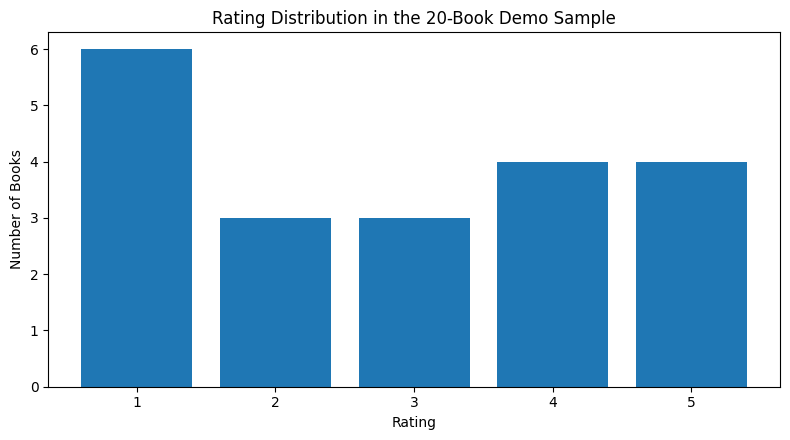

In [27]:
ratings_count = books_scraped_df["rating"].value_counts().sort_index()
plt.figure(figsize=(8, 4.5))
plt.bar(ratings_count.index, ratings_count.values)
plt.title("Rating Distribution in the 20-Book Demo Sample")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.xticks(range(1, 6))
plt.tight_layout()
plt.show()


#### Exploring Patterns

A heatmap is another way to summarise the scraped example. Here, it shows the number of sample books in each price range and rating category. Because these prices and ratings are fictional and only 20 items are included, the heatmap cannot establish a real relationship between a book's price and how readers rate it.


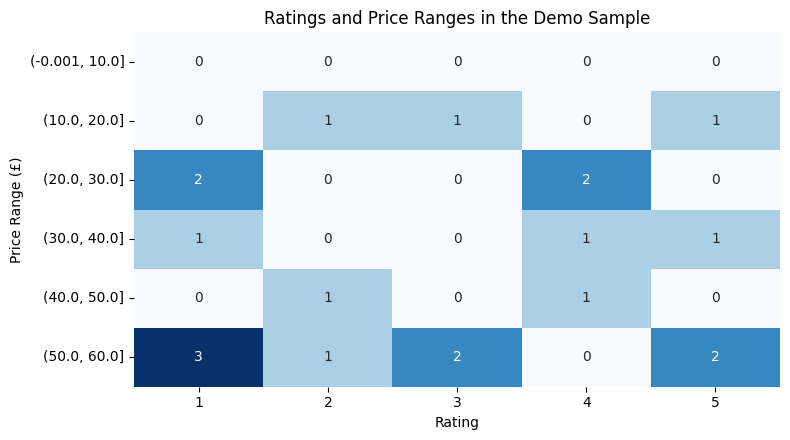

In [28]:
# Use ten-pound bins to make a small frequency table for the heatmap.
books_scraped_df["price_range"] = pd.cut(
    books_scraped_df["price"], bins=np.linspace(0, 60, 7), include_lowest=True
)
heatmap_data = (
    books_scraped_df.groupby(["price_range", "rating"], observed=False)
    .size().unstack(fill_value=0).reindex(columns=range(1, 6), fill_value=0)
)

plt.figure(figsize=(8, 4.5))
sns.heatmap(heatmap_data, cmap="Blues", annot=True, fmt="d", cbar=False)
plt.title("Ratings and Price Ranges in the Demo Sample")
plt.xlabel("Rating")
plt.ylabel("Price Range (£)")
plt.tight_layout()
plt.show()


### 10.0 Conclusions

This exploratory analysis examined the relationships between book length, recorded ratings and book popularity. In the selected sample of **9,664** English-language book records, length and average rating have a **weak positive Pearson correlation** (*r* ≈ **0.203**). The number of ratings and average rating show almost no linear association (*r* ≈ **0.049**). These findings are descriptive and do not establish what causes readers to prefer a book.

Grouping the books by page ranges makes differences easier to visualise, but correlations should use the original book-level observations rather than the group averages. The data may contain different editions of the same title and is restricted by the chosen language and page-length filters, which affect the conclusions.

The secondary data demonstrates collecting and formatting HTML data with Beautiful Soup. Its 20 fictional prices and ratings do not provide evidence about real-world book prices or reader preferences.

Further research could examine how ratings vary by author or publication year and include information about genres and book editions. A larger study would also need to consider who contributes ratings and how representative those users are.


### References

Beautiful Soup Documentation (2023) Available at: https://www.crummy.com/software/BeautifulSoup/bs4/doc/ (Accessed: 20th December 2024)

Books to Scrape (n.d.) [Practice website with fictional content](https://books.toscrape.com/) (originally accessed December 2024).

Data Camp (2024) *Data Scientist with Python.* Available at: https://app.datacamp.com/learn/career-tracks/associate-data-scientist-in-python (Accessed: 11th December 2024)

Coursera (2024) Google Data Analytics Professional Certificate. Available at: https://www.coursera.org/professional-certificates/google-data-analytics (Accessed: 2021 - 2022)

Goodreads-books dataset (Kaggle): https://www.kaggle.com/datasets/jealousleopard/goodreadsbooks (source of the supplied `books.csv`).

Matplotlib (2024) *Examples* Available at: https://matplotlib.org/stable/gallery/index.html (Accessed: 28th December 2024)

Pandas documentation (2024) *pandas.io.formats.style.Styler.set_table_styles.*
Available at: https://pandas.pydata.org/docs/reference/api/pandas.io.formats.style.Styler.set_table_styles.html (Accessed: 10th December 2024)

Pandas documentation (2024) *Table Visualization.*
Available at: https://pandas.pydata.org/docs/user_guide/style.html (Accessed: 10th December 2024)

Python built-in types (2023) Available at: https://docs.python.org/3/library/stdtypes.html (Accessed: 10th December 2024)

Saunders, M., Lewis, P., & Thornhill, A. (2019). Research Methods for Business Students. 8th edn. Harlow: Pearson.

University of London (2024) *Programming with data module.* Available at: https://www.coursera.org/learn/uol-cm2015-programming-with-data (Accessed: 11th December 2024)
